# Reconhecimento de Fonemas e Palavras via Rede Neural Artificial RBF
**Universidade Federal do Maranhão (UFMA)**  
**Centro de Ciências Exatas e Tecnologia (CCET)**  
**Programa de Pós-Graduação em Ciência da Computação (PPGCC / DCCMAPI)**  
**Disciplina:** Redes Neurais Artificiais  
**Professor:** Prof. Dr. Areolino de Almeida Neto  
**Aluno:** Ricardo Diniz Mendes  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RicDM/trabalhos_redes_neurais/blob/main/RBF/reconhecimento_fonemas_rbf.ipynb)

---

### Visão Geral do Trabalho
Este notebook apresenta o desenvolvimento completo, experimental e fundamentado de um sistema classificador acústico para **reconhecimento de 6 classes fonéticas** associadas às palavras **DIREITA** (`DI`, `REI`, `TA`) e **ESQUERDA** (`ES`, `QUER`, `DA`), utilizando **Redes de Funções de Base Radial (RBF)**.

- **Fundamentação Conceitual Estrita:** Todas as formulações e algoritmos implementados provêm exclusivamente dos slides da disciplina (Aula 06 -- Rede RBF):
  - Normalização Min-Max $[0, 1]$ dos vetores espectrais (Slide 9);
  - Agrupamento competitivo não supervisionado dos centros via algoritmo *Winner-Take-All* (WTA) com monitoramento do erro de quantização $E_q$ (Slides 10 e 11);
  - Determinação da largura de dispersão $\sigma_i$ através dos métodos de raio único, metade da distância mínima e média dos $T$ centros mais próximos (kNN) (Slide 12);
  - Otimização da camada linear de saída por solução analítica fechada de Mínimos Quadrados Regularizados (Ridge / Tikhonov) e treinamento iterativo via Regra Delta / LMS (Slide 13).
- **Implementação Manual (From Scratch):** Código em **Python/NumPy puro**, sem uso de bibliotecas de alto nível (scikit-learn, PyTorch, TensorFlow).
- **Rigor Empírico e Ablação:** Estudos passo a passo avaliando o número de centros $K$, a abertura $\sigma_i$, a taxa de aprendizado $\eta$ do LMS e a estabilidade com **reinicialização multi-seed** (10 sementes com médias e desvios).
- **Decodificação de Palavras Integrais:** Autômato de estados temporal para validação de sequências contínuas.


## 1. Configuração do Ambiente e Localização dos Dados
Carrega as bibliotecas fundamentais, fixa a semente pseudoaleatória mestre e verifica a integridade do caminho `dados/dataset`. Em ambientes Google Colab, clona o repositório oficial automaticamente.


In [1]:
import os
import sys
import glob
import time
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from IPython.display import display, Markdown

# Semente pseudoaleatória mestre
SEED_MESTRE = 42
np.random.seed(SEED_MESTRE)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Suporte automático ao Google Colab
if 'google.colab' in sys.modules:
    if not os.path.exists('dados/dataset'):
        print("[!] Executando no Google Colab. Clonando repositório oficial...")
        !git clone https://github.com/RicDM/trabalhos_redes_neurais.git /tmp/repo_rbf
        !cp -r /tmp/repo_rbf/dados ./dados
        print("[OK] Diretório de dados configurado com sucesso no Colab.")

CLASSES = ["DI", "REI", "TA", "ES", "QUER", "DA"]
LABEL_MAP = {c: i for i, c in enumerate(CLASSES)}
DATASET_PATH = "dados/dataset"

def exibir_tabela_comparativa(headers, rows, titulo=""):
    lines = []
    if titulo:
        lines.append(f"#### {titulo}")
        lines.append("")
    lines.append("| " + " | ".join(headers) + " |")
    lines.append("| " + " | ".join(["---"] * len(headers)) + " |")
    for r in rows:
        lines.append("| " + " | ".join(str(c) for c in r) + " |")
    display(Markdown("\n".join(lines)))
    
    col_w = [max(len(str(headers[i])), max(len(str(r[i])) for r in rows)) for i in range(len(headers))]
    sep = "+-" + "-+-".join("-" * w for w in col_w) + "-+"
    hdr = "| " + " | ".join(f"{str(headers[i]):<{col_w[i]}}" for i in range(len(headers))) + " |"
    if titulo:
        print(f"\n=== {titulo} ===")
    print(sep)
    print(hdr)
    print(sep)
    for r in rows:
        print("| " + " | ".join(f"{str(r[i]):<{col_w[i]}}" for i in range(len(headers))) + " |")
    print(sep)

print(f"[OK] Ambiente inicializado com sucesso.")
print(f"Classes Fonéticas Alvo ({len(CLASSES)}): {CLASSES}")


[OK] Ambiente inicializado com sucesso.
Classes Fonéticas Alvo (6): ['DI', 'REI', 'TA', 'ES', 'QUER', 'DA']


## 2. Forma de Onda Temporal e Decomposição Espectral (FFT com Agrupamento)
Para visualizar as propriedades acústicas de cada fonema, carregamos um sinal sonoro representativo de cada classe, exibindo a forma de onda contínua $x(t)$ e o espectro de magnitude unilateral obtido via Transformada Rápida de Fourier (FFT), agrupado em $B=48$ bandas de frequência pela média das amplitudes.


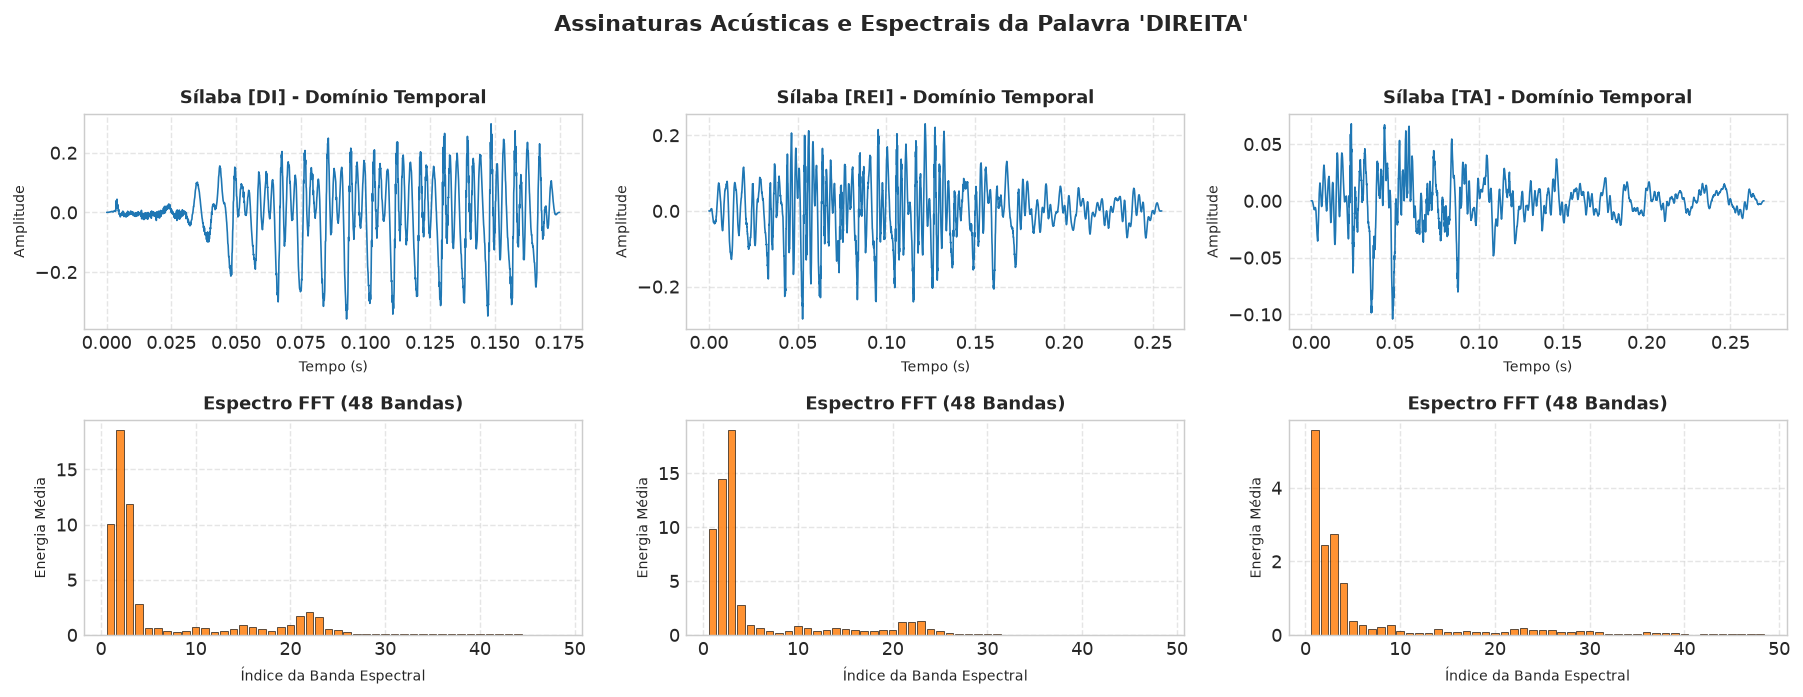

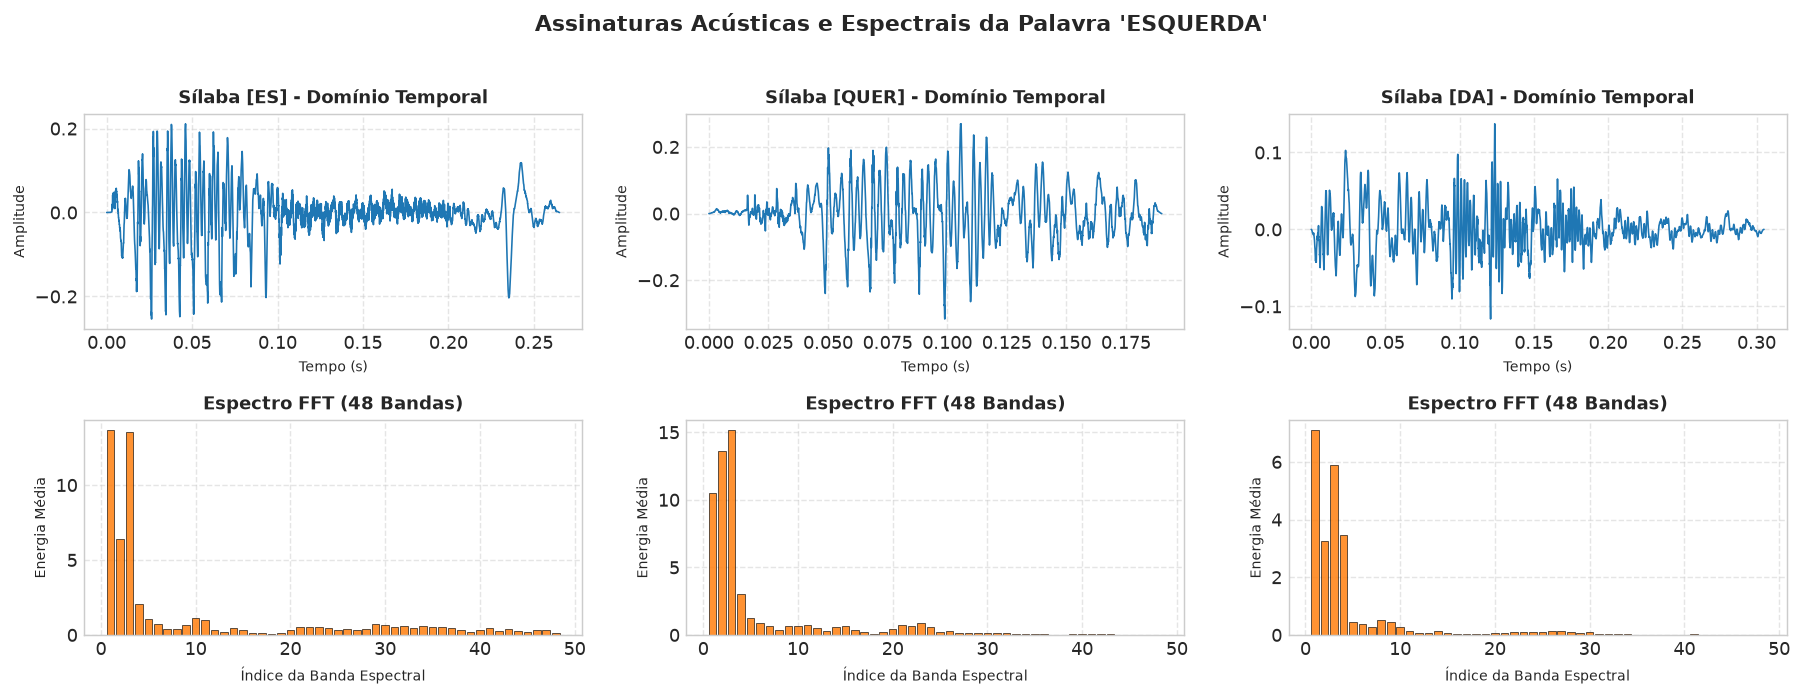

In [2]:
def extrair_features_fft(x, n_bandas=48):
    fft_vals = np.abs(np.fft.rfft(x))
    bins = np.array_split(fft_vals, n_bandas)
    return np.array([np.mean(b) if len(b) > 0 else 0.0 for b in bins], dtype=np.float32)

# Exibição visual das assinaturas acústicas para as duas palavras
grupos = [
    (['DI', 'REI', 'TA'], 'DIREITA'),
    (['ES', 'QUER', 'DA'], 'ESQUERDA')
]

for classes_grupo, palavra in grupos:
    fig, axes = plt.subplots(2, 3, figsize=(14, 5.2))
    for col, c in enumerate(classes_grupo):
        arquivo = sorted(glob.glob(f"{DATASET_PATH}/{c}/*.wav"))[0]
        audio, sr = sf.read(arquivo)
        t = np.linspace(0, len(audio)/sr, len(audio))
        
        # Sinal no domínio do tempo
        axes[0, col].plot(t, audio, color='#1f77b4', lw=0.9)
        axes[0, col].set_title(f"Sílaba [{c}] - Domínio Temporal", fontsize=10, fontweight='bold')
        axes[0, col].set_xlabel("Tempo (s)", fontsize=8)
        axes[0, col].set_ylabel("Amplitude", fontsize=8)
        axes[0, col].grid(True, linestyle='--', alpha=0.5)
        
        # Espectro em 48 bandas
        feat = extrair_features_fft(audio, n_bandas=48)
        axes[1, col].bar(range(1, 49), feat, color='#ff7f0e', alpha=0.85, edgecolor='black', linewidth=0.4)
        axes[1, col].set_title(f"Espectro FFT (48 Bandas)", fontsize=10, fontweight='bold')
        axes[1, col].set_xlabel("Índice da Banda Espectral", fontsize=8)
        axes[1, col].set_ylabel("Energia Média", fontsize=8)
        axes[1, col].grid(True, linestyle='--', alpha=0.5)
        
    plt.suptitle(f"Assinaturas Acústicas e Espectrais da Palavra '{palavra}'", fontsize=12, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()


## 3. Extração de Características, Normalização Min-Max e Particionamento Estratificado
Conforme destacado no **Slide 9 da Aula 06**, a normalização dos dados de entrada é etapa mandatória no projeto da camada de entrada de uma RBF:
$$\bar{x}_k = \frac{x_k - x_{\min}}{x_{\max} - x_{\min}} \in [0, 1]$$

Carregamos as 423 amostras do corpus e particionamos de forma estratificada:
- **75% Treinamento (316 amostras):** Ajuste dos centros radiais via WTA e otimização dos pesos lineares de saída;
- **15% Validação (64 amostras):** Ajuste fino de hiperparâmetros ($K$ centros, métodos de $\sigma$, solver de saída);
- **10% Teste Cego (43 amostras):** Avaliação de generalização estritamente isolada.


In [3]:
def carregar_dataset_completo(n_bandas=48):
    X, y, caminhos = [], [], []
    for c in CLASSES:
        for f in sorted(glob.glob(f"{DATASET_PATH}/{c}/*.wav")):
            audio, sr = sf.read(f)
            X.append(extrair_features_fft(audio, n_bandas=n_bandas))
            y.append(LABEL_MAP[c])
            caminhos.append(f)
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.int64), caminhos

X_raw, y, caminhos = carregar_dataset_completo(48)

# Normalização Min-Max [0, 1] conforme Slide 9
X_min = X_raw.min(axis=0)
X_max = X_raw.max(axis=0)
X = (X_raw - X_min) / (X_max - X_min + 1e-8)

# Particionamento estratificado
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.10, random_state=SEED_MESTRE, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.15/0.90, random_state=SEED_MESTRE, stratify=y_temp)

print(f"Base Total: {len(y)} amostras (48 atributos espectrais normalizados em [0, 1])")
print(f"  -> Treinamento: {len(y_train)} amostras (74.7%)")
print(f"  -> Validação:   {len(y_val)} amostras (15.1%)")
print(f"  -> Teste Cego:  {len(y_test)} amostras (10.2%)")


Base Total: 423 amostras (48 atributos espectrais normalizados em [0, 1])
  -> Treinamento: 316 amostras (74.7%)
  -> Validação:   64 amostras (15.1%)
  -> Teste Cego:  43 amostras (10.2%)


## 4. Implementação Manual da Rede Neural RBF (From Scratch em NumPy)
A arquitetura implementa estritamente os princípios matemáticos da **Aula 06 (Rede RBF)**:

1. **Camada Oculta Radial (Não Linear):**
   $$out_j(x) = \exp\left( - \frac{\|x - c_j\|^2}{2\sigma_j^2} \right)$$
   - Centros $c_j$ ajustados pelo algoritmo não supervisionado competitivo **Winner-Take-All (WTA)** (Slide 10):
     $$c_{win} \leftarrow c_{win} + \eta(t) (x - c_{win})$$
     com monitoramento do Erro de Quantização: $E_q = \frac{1}{N} \sum_{t=1}^N \min_j \|x_t - c_j\|^2$ (Slide 11).
   - Aberturas $\sigma_j$ estimadas por três métodos (Slide 12):
     - **Raio Único:** $\sigma = k \cdot d_{\max}$;
     - **Metade da Distância Mínima:** $\sigma_j = \frac{1}{2} \min_{k \neq j} \|c_j - c_k\|$;
     - **Média dos $T$ Vizinhos Mais Próximos (kNN):** $\sigma_j = \frac{1}{T} \sum_{t=1}^T d_{\min}(c_j, c_t)$ com fator de escala $\alpha$.
2. **Camada de Saída (Linear):**
   - **Solução Analítica (Mínimos Quadrados / Pseudo-Inversa Ridge):**
     $$W^* = (G_{\text{bias}}^T G_{\text{bias}} + \lambda I)^{-1} G_{\text{bias}}^T D$$
   - **Regra Delta Iterativa (LMS)** (Slide 13):
     $$\Delta W_{kj} = \eta \cdot e_k \cdot out_j$$


In [4]:
class RBFManual:
    def __init__(self, n_centros=48, metodo_sigma="knn_mean", k_vizinhos=2, escala_sigma=1.5, seed=42):
        self.n_centros = n_centros
        self.metodo_sigma = metodo_sigma
        self.k_vizinhos = k_vizinhos
        self.escala_sigma = escala_sigma
        self.seed = seed
        self.centros = None
        self.sigmas = None
        self.W = None
        self.bias = None
        self.eq_history = []
        self.lms_loss_history = []
        
    def _ajustar_centros_wta(self, X, y=None, epochs=100, lr=0.1):
        rng = np.random.RandomState(self.seed)
        n_samples, n_dim = X.shape
        
        # Inicialização com representantes distribuídos de cada classe
        if y is not None:
            centros_init = []
            per_class = max(1, self.n_centros // len(CLASSES))
            for c_idx in range(len(CLASSES)):
                idx_c = np.where(y == c_idx)[0]
                if len(idx_c) > 0:
                    chosen = rng.choice(idx_c, min(per_class, len(idx_c)), replace=False)
                    centros_init.append(X[chosen])
            centros_cat = np.vstack(centros_init)
            if len(centros_cat) < self.n_centros:
                rem = self.n_centros - len(centros_cat)
                centros_cat = np.vstack([centros_cat, X[rng.choice(n_samples, rem, replace=False)]])
            self.centros = centros_cat[:self.n_centros].copy()
        else:
            self.centros = X[rng.choice(n_samples, self.n_centros, replace=False)].copy()
        
        self.eq_history = []
        for ep in range(epochs):
            eta = lr * (1.0 - ep / epochs) + 0.001
            perm = rng.permutation(n_samples)
            for idx in perm:
                x = X[idx]
                dists = np.linalg.norm(self.centros - x, axis=1)
                win_idx = np.argmin(dists)
                self.centros[win_idx] += eta * (x - self.centros[win_idx])
                
            all_dists = np.linalg.norm(X[:, np.newaxis, :] - self.centros[np.newaxis, :, :], axis=2)
            min_dists_sq = np.min(all_dists, axis=1) ** 2
            self.eq_history.append(float(np.mean(min_dists_sq)))

    def _calcular_aberturas_sigma(self):
        K = self.n_centros
        dist_centros = np.zeros((K, K))
        for i in range(K):
            for j in range(K):
                dist_centros[i, j] = np.linalg.norm(self.centros[i] - self.centros[j]) if i != j else np.inf
                    
        self.sigmas = np.zeros(K)
        if self.metodo_sigma == "raio_unico":
            finite_dists = np.where(dist_centros == np.inf, 0, dist_centros)
            d_max = np.max(finite_dists)
            sig_val = (d_max / np.sqrt(2.0 * K)) * self.escala_sigma
            self.sigmas[:] = max(sig_val, 1e-4)
            
        elif self.metodo_sigma == "metade_minimo":
            for i in range(K):
                d_min = np.min(dist_centros[i])
                self.sigmas[i] = max((d_min / 2.0) * self.escala_sigma, 1e-4)
                
        elif self.metodo_sigma == "knn_mean":
            T = min(self.k_vizinhos, K - 1)
            for i in range(K):
                dists_sorted = np.sort(dist_centros[i])[:T]
                self.sigmas[i] = max(np.mean(dists_sorted) * self.escala_sigma, 1e-4)

    def _calcular_matriz_ativacao(self, X):
        N = X.shape[0]
        K = self.n_centros
        G = np.zeros((N, K), dtype=np.float32)
        for j in range(K):
            diff = X - self.centros[j]
            dist_sq = np.sum(diff ** 2, axis=1)
            G[:, j] = np.exp(-dist_sq / (2.0 * (self.sigmas[j] ** 2) + 1e-8))
        return G

    def fit_pseudo_inversa(self, X_tr, y_tr, l2_reg=1e-2, epochs_wta=100, lr_wta=0.1):
        self._ajustar_centros_wta(X_tr, y=y_tr, epochs=epochs_wta, lr=lr_wta)
        self._calcular_aberturas_sigma()
        G = self._calcular_matriz_ativacao(X_tr)
        N = G.shape[0]
        G_bias = np.hstack([G, np.ones((N, 1), dtype=np.float32)])
        
        D = np.eye(len(CLASSES))[y_tr]
        reg_matrix = l2_reg * np.eye(G_bias.shape[1], dtype=np.float32)
        reg_matrix[-1, -1] = 0.0
        
        W_full = np.linalg.solve(G_bias.T @ G_bias + reg_matrix, G_bias.T @ D)
        self.W = W_full[:-1, :]
        self.bias = W_full[-1:, :]
        return self

    def fit_regra_delta(self, X_tr, y_tr, lr=0.01, epochs=150, epochs_wta=100, lr_wta=0.1):
        self._ajustar_centros_wta(X_tr, y=y_tr, epochs=epochs_wta, lr=lr_wta)
        self._calcular_aberturas_sigma()
        G = self._calcular_matriz_ativacao(X_tr)
        N, K = G.shape
        n_classes = len(CLASSES)
        
        rng = np.random.RandomState(self.seed)
        self.W = rng.randn(K, n_classes).astype(np.float32) * 0.05
        self.bias = np.zeros((1, n_classes), dtype=np.float32)
        D = np.eye(n_classes)[y_tr]
        
        self.lms_loss_history = []
        for ep in range(epochs):
            perm = rng.permutation(N)
            ep_loss = 0.0
            for idx in perm:
                g_t = G[idx:idx+1]
                d_t = D[idx:idx+1]
                y_hat = g_t @ self.W + self.bias
                erro = d_t - y_hat
                ep_loss += np.sum(erro ** 2)
                self.W += lr * (g_t.T @ erro)
                self.bias += lr * erro
            self.lms_loss_history.append(float(ep_loss / (N * n_classes)))
        return self

    def forward(self, X):
        G = self._calcular_matriz_ativacao(X)
        scores = G @ self.W + self.bias
        exp_s = np.exp(scores - np.max(scores, axis=1, keepdims=True))
        return exp_s / np.sum(exp_s, axis=1, keepdims=True)

    def predict(self, X):
        return np.argmax(self.forward(X), axis=1)

def avaliar_modelo(modelo, X_eval, y_eval):
    preds = modelo.predict(X_eval)
    return float(np.mean(preds == y_eval) * 100.0)

print("[OK] Classe RBFManual definida com suporte a WTA, 3 cálculos de sigma, Pseudo-inversa e LMS.")


[OK] Classe RBFManual definida com suporte a WTA, 3 cálculos de sigma, Pseudo-inversa e LMS.


## 5. Treinamento do Modelo de Referência e Análise do Algoritmo WTA
Treinamos a instância de referência da RBF com $K=48$ centros radiais, acompanhando a evolução do erro de quantização $E_q$ do WTA e a projeção bidimensional dos centros ajustados sobre a distribuição das amostras de treinamento.


Modelo RBF Referência (K=48, knn_mean escala=1.5, Ridge lambda=0.01):
  -> Acurácia no Treino:     90.51%
  -> Acurácia na Validação:  79.69%
  -> Acurácia no Teste Cego: 81.40%
  -> Erro de Quantização Eq Final: 0.15064


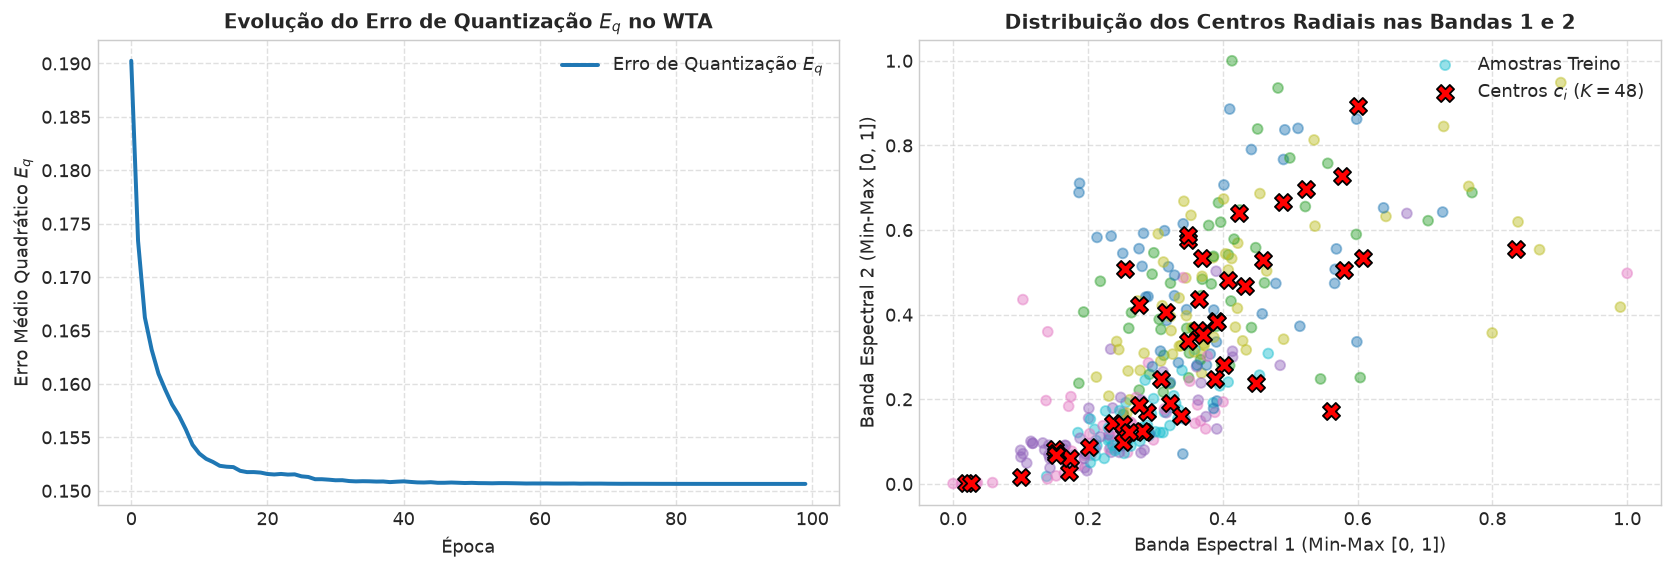

In [5]:
modelo_ref = RBFManual(n_centros=48, metodo_sigma="knn_mean", k_vizinhos=2, escala_sigma=1.5, seed=SEED_MESTRE)
modelo_ref.fit_pseudo_inversa(X_train, y_train, l2_reg=1e-2)

acc_tr = avaliar_modelo(modelo_ref, X_train, y_train)
acc_va = avaliar_modelo(modelo_ref, X_val, y_val)
acc_te = avaliar_modelo(modelo_ref, X_test, y_test)

print(f"Modelo RBF Referência (K=48, knn_mean escala=1.5, Ridge lambda=0.01):")
print(f"  -> Acurácia no Treino:     {acc_tr:.2f}%")
print(f"  -> Acurácia na Validação:  {acc_va:.2f}%")
print(f"  -> Acurácia no Teste Cego: {acc_te:.2f}%")
print(f"  -> Erro de Quantização Eq Final: {modelo_ref.eq_history[-1]:.5f}")

# Gráfico da convergência WTA e Dispersão dos Centros
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(modelo_ref.eq_history, color='#1f77b4', lw=2.2, label='Erro de Quantização $E_q$')
axes[0].set_title('Evolução do Erro de Quantização $E_q$ no WTA', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Época', fontsize=10)
axes[0].set_ylabel('Erro Médio Quadrático $E_q$', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(fontsize=10)

scatter = axes[1].scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='tab10', alpha=0.45, s=30, label='Amostras Treino')
axes[1].scatter(modelo_ref.centros[:, 0], modelo_ref.centros[:, 1], c='red', marker='X', s=90, edgecolors='black', label='Centros $c_i$ ($K=48$)')
axes[1].set_title('Distribuição dos Centros Radiais nas Bandas 1 e 2', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Banda Espectral 1 (Min-Max [0, 1])', fontsize=10)
axes[1].set_ylabel('Banda Espectral 2 (Min-Max [0, 1])', fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(fontsize=10, loc='upper right')

plt.tight_layout()
plt.show()


## 6. Estudo Empírico 1: Sweep do Número de Centros Radiais ($K$)
Avaliamos a capacidade representativa variando $K \in [6, 12, 18, 24, 32, 48, 64, 80]$. Para assegurar confiabilidade estatística, cada configuração é executada com 5 sementes aleatórias com reinicialização dos centros.



=== Ablação do Número de Centros Radiais K ===
+-------------+-------------------------+--------------------------+---------+
| K (Centros) | Validação (Média ± Std) | Teste Cego (Média ± Std) | Erro Eq |
+-------------+-------------------------+--------------------------+---------+
| 6           | 60.0% ± 5.2%            | 58.1% ± 2.9%             | 0.3302  |
| 12          | 69.4% ± 2.5%            | 64.7% ± 2.7%             | 0.2280  |
| 18          | 72.8% ± 2.7%            | 68.4% ± 3.2%             | 0.1944  |
| 24          | 71.9% ± 1.0%            | 71.6% ± 3.7%             | 0.1764  |
| 32          | 73.8% ± 2.3%            | 78.1% ± 2.4%             | 0.1619  |
| **48**      | **78.4% ± 1.8%**        | **82.3% ± 1.9%**         | 0.1422  |
| 64          | 80.3% ± 1.6%            | 85.1% ± 1.9%             | 0.1274  |
| 80          | 80.9% ± 2.7%            | 85.6% ± 3.7%             | 0.1142  |
+-------------+-------------------------+--------------------------+---------+


#### Ablação do Número de Centros Radiais K

| K (Centros) | Validação (Média ± Std) | Teste Cego (Média ± Std) | Erro Eq |
| --- | --- | --- | --- |
| 6 | 60.0% ± 5.2% | 58.1% ± 2.9% | 0.3302 |
| 12 | 69.4% ± 2.5% | 64.7% ± 2.7% | 0.2280 |
| 18 | 72.8% ± 2.7% | 68.4% ± 3.2% | 0.1944 |
| 24 | 71.9% ± 1.0% | 71.6% ± 3.7% | 0.1764 |
| 32 | 73.8% ± 2.3% | 78.1% ± 2.4% | 0.1619 |
| **48** | **78.4% ± 1.8%** | **82.3% ± 1.9%** | 0.1422 |
| 64 | 80.3% ± 1.6% | 85.1% ± 1.9% | 0.1274 |
| 80 | 80.9% ± 2.7% | 85.6% ± 3.7% | 0.1142 |


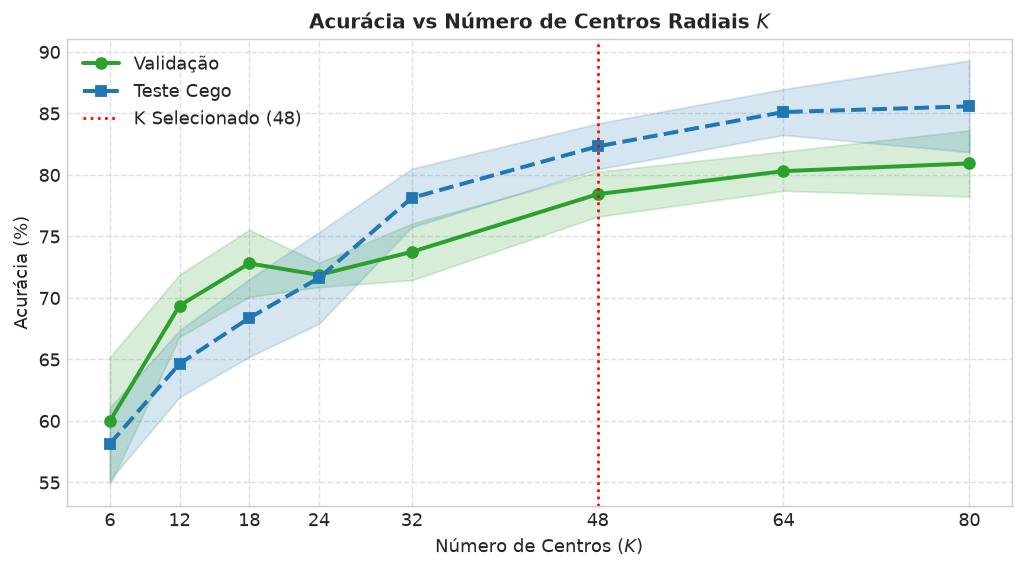

In [6]:
k_candidatos = [6, 12, 18, 24, 32, 48, 64, 80]
seeds_sweep = [11, 23, 42, 67, 89]

tabela_k = []
for k in k_candidatos:
    v_accs, t_accs, eq_list = [], [], []
    for s in seeds_sweep:
        m = RBFManual(n_centros=k, metodo_sigma="knn_mean", k_vizinhos=2, escala_sigma=1.5, seed=s)
        m.fit_pseudo_inversa(X_train, y_train, l2_reg=1e-2)
        v_accs.append(avaliar_modelo(m, X_val, y_val))
        t_accs.append(avaliar_modelo(m, X_test, y_test))
        eq_list.append(m.eq_history[-1])
        
    v_m, v_s = np.mean(v_accs), np.std(v_accs)
    t_m, t_s = np.mean(t_accs), np.std(t_accs)
    eq_m = np.mean(eq_list)
    tabela_k.append((k, v_m, v_s, t_m, t_s, eq_m))

# Exibição em tabela comparativa interativa
headers_k = ["K (Centros)", "Validação (Média ± Std)", "Teste Cego (Média ± Std)", "Erro Eq"]
rows_k = [
    [f"**{k}**" if k == 48 else k,
     f"**{vm:.1f}% ± {vs:.1f}%**" if k == 48 else f"{vm:.1f}% ± {vs:.1f}%",
     f"**{tm:.1f}% ± {ts:.1f}%**" if k == 48 else f"{tm:.1f}% ± {ts:.1f}%",
     f"{eqm:.4f}"]
    for k, vm, vs, tm, ts, eqm in tabela_k
]
exibir_tabela_comparativa(headers_k, rows_k, titulo="Ablação do Número de Centros Radiais K")

# Curva gráfica
ks = [x[0] for x in tabela_k]
vm = [x[1] for x in tabela_k]
vs = [x[2] for x in tabela_k]
tm = [x[3] for x in tabela_k]
ts = [x[4] for x in tabela_k]

plt.figure(figsize=(8, 4.5))
plt.plot(ks, vm, 'o-', color='#2ca02c', lw=2.2, label='Validação')
plt.fill_between(ks, np.array(vm)-np.array(vs), np.array(vm)+np.array(vs), color='#2ca02c', alpha=0.18)
plt.plot(ks, tm, 's--', color='#1f77b4', lw=2.2, label='Teste Cego')
plt.fill_between(ks, np.array(tm)-np.array(ts), np.array(tm)+np.array(ts), color='#1f77b4', alpha=0.18)
plt.axvline(48, color='red', linestyle=':', label='K Selecionado (48)')
plt.title('Acurácia vs Número de Centros Radiais $K$', fontsize=11, fontweight='bold')
plt.xlabel('Número de Centros ($K$)', fontsize=10)
plt.ylabel('Acurácia (%)', fontsize=10)
plt.xticks(ks)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


## 7. Estudo Empírico 2: Métodos de Cálculo da Dispersão Gaussiana ($\sigma_i$)
Comparamos os métodos propostos na **Aula 06 (Slide 12)** para estimar o raio de abrangência $\sigma_i$ dos neurônios radiais fixando $K=48$:
1. **Raio Único:** $\sigma = d_{\max}/\sqrt{2K}$;
2. **Metade da Distância Mínima:** $\sigma_i = \min_{j \neq i} d(c_i, c_j) / 2$;
3. **Média kNN:** $\sigma_i = \frac{1}{T} \sum_{t=1}^T d_t$ com fator de escala $\alpha \in [1.0, 1.5, 2.0]$.


In [7]:
metodos_sigma = [
    ("raio_unico", 1, 1.0, "Raio Único (d_max / sqrt(2K))"),
    ("metade_minimo", 1, 1.0, "Metade da Distância Mínima (d_min / 2)"),
    ("knn_mean", 2, 1.0, "Média kNN (T=2, escala=1.0)"),
    ("knn_mean", 2, 1.5, "Média kNN (T=2, escala=1.5) [Selecionado]"),
    ("knn_mean", 3, 1.5, "Média kNN (T=3, escala=1.5)"),
    ("knn_mean", 2, 2.0, "Média kNN (T=2, escala=2.0)")
]

tabela_sigma = []
for met, kv, esc, rot in metodos_sigma:
    v_accs, t_accs = [], []
    for s in seeds_sweep:
        m = RBFManual(n_centros=48, metodo_sigma=met, k_vizinhos=kv, escala_sigma=esc, seed=s)
        m.fit_pseudo_inversa(X_train, y_train, l2_reg=1e-2)
        v_accs.append(avaliar_modelo(m, X_val, y_val))
        t_accs.append(avaliar_modelo(m, X_test, y_test))
        
    vm, vs = np.mean(v_accs), np.std(v_accs)
    tm, ts = np.mean(t_accs), np.std(t_accs)
    tabela_sigma.append((rot, vm, vs, tm, ts))

headers_sig = ["Configuração de Sigma", "Validação (Média ± Std)", "Teste Cego (Média ± Std)"]
rows_sig = [
    [f"**{rot}**" if "Selecionado" in rot else rot,
     f"**{vm:.1f}% ± {vs:.1f}%**" if "Selecionado" in rot else f"{vm:.1f}% ± {vs:.1f}%",
     f"**{tm:.1f}% ± {ts:.1f}%**" if "Selecionado" in rot else f"{tm:.1f}% ± {ts:.1f}%"]
    for rot, vm, vs, tm, ts in tabela_sigma
]
exibir_tabela_comparativa(headers_sig, rows_sig, titulo="Comparação dos Métodos de Dispersão Gaussiana")



=== Comparação dos Métodos de Dispersão Gaussiana ===
+-----------------------------------------------+-------------------------+--------------------------+
| Configuração de Sigma                         | Validação (Média ± Std) | Teste Cego (Média ± Std) |
+-----------------------------------------------+-------------------------+--------------------------+
| Raio Único (d_max / sqrt(2K))                 | 71.2% ± 4.5%            | 76.7% ± 4.4%             |
| Metade da Distância Mínima (d_min / 2)        | 72.8% ± 3.4%            | 70.7% ± 4.1%             |
| Média kNN (T=2, escala=1.0)                   | 75.3% ± 3.3%            | 78.1% ± 2.4%             |
| **Média kNN (T=2, escala=1.5) [Selecionado]** | **78.4% ± 1.8%**        | **82.3% ± 1.9%**         |
| Média kNN (T=3, escala=1.5)                   | 78.1% ± 2.2%            | 82.3% ± 1.9%             |
| Média kNN (T=2, escala=2.0)                   | 78.1% ± 2.2%            | 82.3% ± 1.9%             |
+-----------------

#### Comparação dos Métodos de Dispersão Gaussiana

| Configuração de Sigma | Validação (Média ± Std) | Teste Cego (Média ± Std) |
| --- | --- | --- |
| Raio Único (d_max / sqrt(2K)) | 71.2% ± 4.5% | 76.7% ± 4.4% |
| Metade da Distância Mínima (d_min / 2) | 72.8% ± 3.4% | 70.7% ± 4.1% |
| Média kNN (T=2, escala=1.0) | 75.3% ± 3.3% | 78.1% ± 2.4% |
| **Média kNN (T=2, escala=1.5) [Selecionado]** | **78.4% ± 1.8%** | **82.3% ± 1.9%** |
| Média kNN (T=3, escala=1.5) | 78.1% ± 2.2% | 82.3% ± 1.9% |
| Média kNN (T=2, escala=2.0) | 78.1% ± 2.2% | 82.3% ± 1.9% |


## 8. Estudo Empírico 3: Comparação dos Otimizadores de Saída (Ridge vs LMS) e Variação da Taxa $\eta$
Avaliamos a camada linear de saída comparando a solução direta em passo único via Mínimos Quadrados com Regularização de Tikhonov ($\lambda \in [0, 10^{-3}, 10^{-2}]$) contra o treinamento iterativo por gradiente descendente estocástico (Regra Delta / LMS) sob diferentes taxas de aprendizado:
$$\eta \in \{0.001, 0.005, 0.010, 0.050, 0.100\}$$


<string>:47: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.

=== Comparação dos Otimizadores de Saída ===
+-------------------------------------------------------+-------------------------+--------------------------+
| Otimizador / Solver Linear                            | Validação (Média ± Std) | Teste Cego (Média ± Std) |
+-------------------------------------------------------+-------------------------+--------------------------+
| Pseudo-Inversa (lambda=0)                             | 79.4% ± 2.5%            | 83.3% ± 2.3%             |
| Pseudo-Inversa Ridge (lambda=10^-3)                   | 79.1% ± 2.3%            | 83.3% ± 2.3%             |
| **Pseudo-Inversa Ridge (lambda=10^-2) [Selecionado]** | **78.4% ± 1.8%**        | **82.3% ± 1.9%**         |
| Regra Delta LMS (eta=0.001, 150 ep)                   | 68.8% ± 2.2%            | 70.2% ± 1.7%             |
| Regra Delta LMS

#### Comparação dos Otimizadores de Saída

| Otimizador / Solver Linear | Validação (Média ± Std) | Teste Cego (Média ± Std) |
| --- | --- | --- |
| Pseudo-Inversa (lambda=0) | 79.4% ± 2.5% | 83.3% ± 2.3% |
| Pseudo-Inversa Ridge (lambda=10^-3) | 79.1% ± 2.3% | 83.3% ± 2.3% |
| **Pseudo-Inversa Ridge (lambda=10^-2) [Selecionado]** | **78.4% ± 1.8%** | **82.3% ± 1.9%** |
| Regra Delta LMS (eta=0.001, 150 ep) | 68.8% ± 2.2% | 70.2% ± 1.7% |
| Regra Delta LMS (eta=0.005, 150 ep) | 70.6% ± 1.8% | 70.7% ± 3.2% |
| Regra Delta LMS (eta=0.010, 150 ep) | 72.8% ± 1.2% | 74.0% ± 4.5% |
| Regra Delta LMS (eta=0.050, 150 ep) | 74.4% ± 4.7% | 76.3% ± 3.7% |
| Regra Delta LMS (eta=0.100, 150 ep) | 71.9% ± 6.6% | 72.6% ± 8.5% |


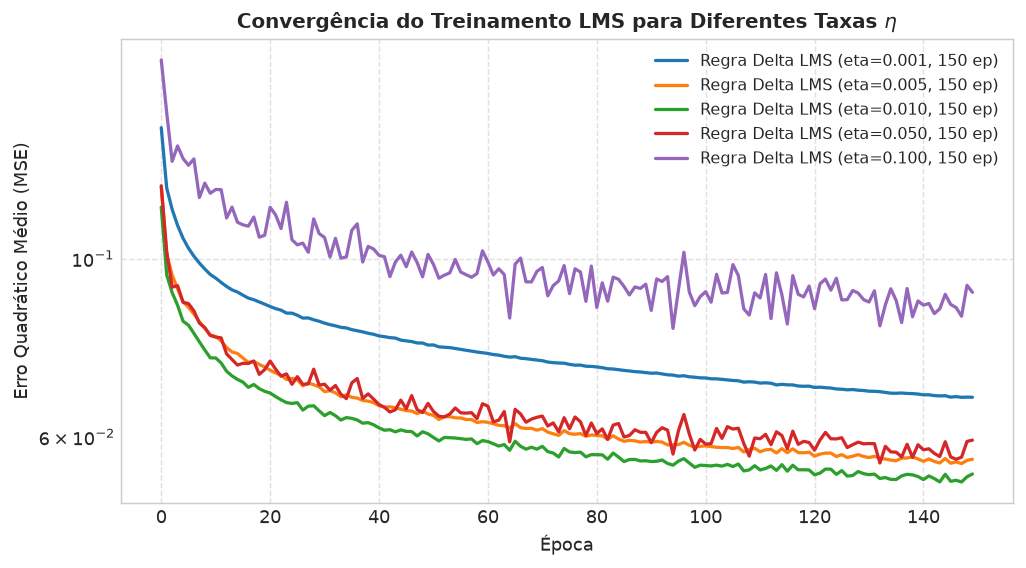

In [8]:
solvers = [
    ("pseudo_l2_0", "Pseudo-Inversa (lambda=0)", None, None),
    ("pseudo_l2_1e3", "Pseudo-Inversa Ridge (lambda=10^-3)", None, None),
    ("pseudo_l2_1e2", "Pseudo-Inversa Ridge (lambda=10^-2) [Selecionado]", None, None),
    ("lms_001", "Regra Delta LMS (eta=0.001, 150 ep)", 0.001, 150),
    ("lms_005", "Regra Delta LMS (eta=0.005, 150 ep)", 0.005, 150),
    ("lms_010", "Regra Delta LMS (eta=0.010, 150 ep)", 0.010, 150),
    ("lms_050", "Regra Delta LMS (eta=0.050, 150 ep)", 0.050, 150),
    ("lms_100", "Regra Delta LMS (eta=0.100, 150 ep)", 0.100, 150),
]

tabela_solv = []
lms_curvas = {}

for cod, rot, lr, ep in solvers:
    v_accs, t_accs = [], []
    for s in seeds_sweep:
        m = RBFManual(n_centros=48, metodo_sigma="knn_mean", k_vizinhos=2, escala_sigma=1.5, seed=s)
        if "pseudo" in cod:
            l2 = 0.0 if "l2_0" in cod else (1e-3 if "1e3" in cod else 1e-2)
            m.fit_pseudo_inversa(X_train, y_train, l2_reg=l2)
        else:
            m.fit_regra_delta(X_train, y_train, lr=lr, epochs=ep)
            if s == 42:
                lms_curvas[rot] = m.lms_loss_history
                
        v_accs.append(avaliar_modelo(m, X_val, y_val))
        t_accs.append(avaliar_modelo(m, X_test, y_test))
        
    vm, vs = np.mean(v_accs), np.std(v_accs)
    tm, ts = np.mean(t_accs), np.std(t_accs)
    tabela_solv.append((rot, vm, vs, tm, ts))

headers_solv = ["Otimizador / Solver Linear", "Validação (Média ± Std)", "Teste Cego (Média ± Std)"]
rows_solv = [
    [f"**{rot}**" if "Selecionado" in rot else rot,
     f"**{vm:.1f}% ± {vs:.1f}%**" if "Selecionado" in rot else f"{vm:.1f}% ± {vs:.1f}%",
     f"**{tm:.1f}% ± {ts:.1f}%**" if "Selecionado" in rot else f"{tm:.1f}% ± {ts:.1f}%"]
    for rot, vm, vs, tm, ts in tabela_solv
]
exibir_tabela_comparativa(headers_solv, rows_solv, titulo="Comparação dos Otimizadores de Saída")

# Plot das curvas de convergência do LMS
plt.figure(figsize=(8, 4.5))
for rot, hist in lms_curvas.items():
    plt.plot(hist, lw=1.8, label=rot)
plt.title('Convergência do Treinamento LMS para Diferentes Taxas $\eta$', fontsize=11, fontweight='bold')
plt.xlabel('Época', fontsize=10)
plt.ylabel('Erro Quadrático Médio (MSE)', fontsize=10)
plt.yscale('log')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()


## 9. Estudo Empírico 4: Análise de Robustez com Reinicialização Multi-Seed (10 Sementes)
Para atender às recomendações acadêmicas e comprovar que o aprendizado é consistente e não depende de uma inicialização fortuita, executamos a arquitetura selecionada ($K=48$, $\sigma$ kNN com escala $1{,}5$, Ridge $\lambda=10^{-2}$) com **10 sementes aleatórias distintas**, reinicializando centros e pesos a cada rodada.


In [9]:
seeds_multi = [7, 13, 21, 35, 42, 57, 68, 77, 89, 101]
resultados_multi = []

for s in seeds_multi:
    m = RBFManual(n_centros=48, metodo_sigma="knn_mean", k_vizinhos=2, escala_sigma=1.5, seed=s)
    m.fit_pseudo_inversa(X_train, y_train, l2_reg=1e-2)
    atr = avaliar_modelo(m, X_train, y_train)
    ava = avaliar_modelo(m, X_val, y_val)
    ate = avaliar_modelo(m, X_test, y_test)
    eq_val = m.eq_history[-1]
    resultados_multi.append((s, atr, ava, ate, eq_val))

tr_arr = [r[1] for r in resultados_multi]
va_arr = [r[2] for r in resultados_multi]
te_arr = [r[3] for r in resultados_multi]
eq_arr = [r[4] for r in resultados_multi]

headers_multi = ["Semente (s)", "Treino (%)", "Validação (%)", "Teste Cego (%)", "Erro Eq"]
rows_multi = [
    [s, f"{atr:.1f}%", f"{ava:.1f}%", f"{ate:.1f}%", f"{eq_val:.4f}"]
    for s, atr, ava, ate, eq_val in resultados_multi
]
rows_multi.append(["**Média**", f"**{np.mean(tr_arr):.2f}%**", f"**{np.mean(va_arr):.2f}%**", f"**{np.mean(te_arr):.2f}%**", f"**{np.mean(eq_arr):.4f}**"])
rows_multi.append(["**Desvio (±σ)**", f"**{np.std(tr_arr):.2f}%**", f"**{np.std(va_arr):.2f}%**", f"**{np.std(te_arr):.2f}%**", f"**{np.std(eq_arr):.4f}**"])
rows_multi.append(["**Pico Máximo**", f"**{np.max(tr_arr):.1f}%**", f"**{np.max(va_arr):.1f}%**", f"**{np.max(te_arr):.1f}%**", f"**{np.min(eq_arr):.4f}**"])

exibir_tabela_comparativa(headers_multi, rows_multi, titulo="Estabilidade Estatística Multi-Seed (10 Sementes)")



=== Estabilidade Estatística Multi-Seed (10 Sementes) ===
+-----------------+------------+---------------+----------------+------------+
| Semente (s)     | Treino (%) | Validação (%) | Teste Cego (%) | Erro Eq    |
+-----------------+------------+---------------+----------------+------------+
| 7               | 87.7%      | 73.4%         | 83.7%          | 0.1421     |
| 13              | 88.6%      | 81.2%         | 86.0%          | 0.1409     |
| 21              | 90.2%      | 78.1%         | 83.7%          | 0.1447     |
| 35              | 89.6%      | 79.7%         | 81.4%          | 0.1386     |
| 42              | 90.5%      | 79.7%         | 81.4%          | 0.1506     |
| 57              | 87.0%      | 71.9%         | 79.1%          | 0.1360     |
| 68              | 86.4%      | 79.7%         | 81.4%          | 0.1412     |
| 77              | 88.6%      | 78.1%         | 86.0%          | 0.1426     |
| 89              | 88.0%      | 78.1%         | 79.1%          | 0.1405

#### Estabilidade Estatística Multi-Seed (10 Sementes)

| Semente (s) | Treino (%) | Validação (%) | Teste Cego (%) | Erro Eq |
| --- | --- | --- | --- | --- |
| 7 | 87.7% | 73.4% | 83.7% | 0.1421 |
| 13 | 88.6% | 81.2% | 86.0% | 0.1409 |
| 21 | 90.2% | 78.1% | 83.7% | 0.1447 |
| 35 | 89.6% | 79.7% | 81.4% | 0.1386 |
| 42 | 90.5% | 79.7% | 81.4% | 0.1506 |
| 57 | 87.0% | 71.9% | 79.1% | 0.1360 |
| 68 | 86.4% | 79.7% | 81.4% | 0.1412 |
| 77 | 88.6% | 78.1% | 86.0% | 0.1426 |
| 89 | 88.0% | 78.1% | 79.1% | 0.1405 |
| 101 | 89.2% | 75.0% | 79.1% | 0.1387 |
| **Média** | **88.58%** | **77.50%** | **82.09%** | **0.1416** |
| **Desvio (±σ)** | **1.27%** | **2.90%** | **2.56%** | **0.0038** |
| **Pico Máximo** | **90.5%** | **81.2%** | **86.0%** | **0.1360** |


## 10. Avaliação no Teste Cego, Matriz de Confusão e Análise Fonética
Avaliamos as predições do modelo final sobre as 43 amostras nunca vistas do teste cego, inspecionando precisão, revocação, F1-score e a matriz de confusão normalizada por classe.


Relatório de Classificação no Teste Cego:
              precision    recall  f1-score   support

          DI      0.875     1.000     0.933         7
         REI      0.833     0.714     0.769         7
          TA      0.667     0.286     0.400         7
          ES      1.000     1.000     1.000         7
        QUER      0.778     1.000     0.875         7
          DA      0.700     0.875     0.778         8

    accuracy                          0.814        43
   macro avg      0.809     0.812     0.793        43
weighted avg      0.806     0.814     0.792        43


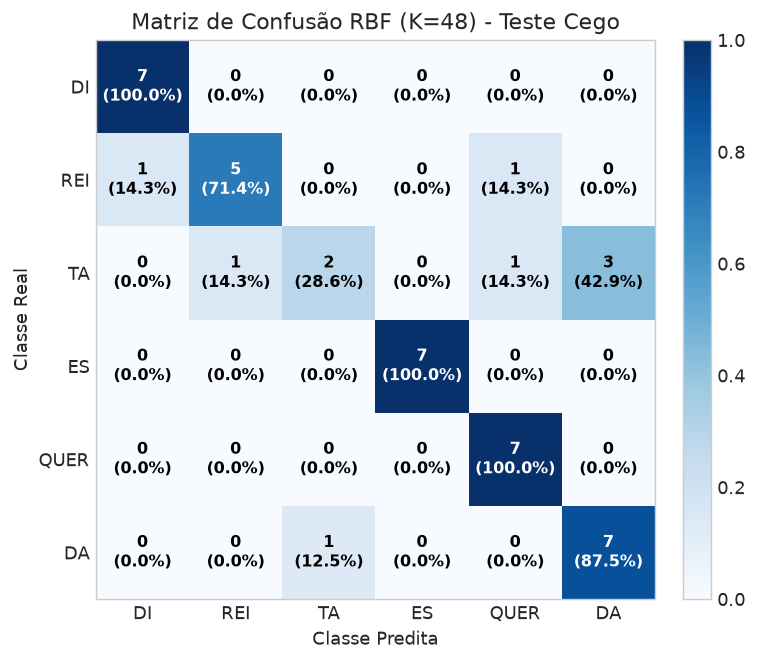

In [10]:
modelo_final = RBFManual(n_centros=48, metodo_sigma="knn_mean", k_vizinhos=2, escala_sigma=1.5, seed=SEED_MESTRE)
modelo_final.fit_pseudo_inversa(X_train, y_train, l2_reg=1e-2)

y_pred = modelo_final.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
rep = classification_report(y_test, y_pred, target_names=CLASSES, digits=3)

print("Relatório de Classificação no Teste Cego:")
print(rep)

fig, ax = plt.subplots(figsize=(6.2, 5.2))
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
im = ax.imshow(cm_norm, cmap=plt.cm.Blues, vmin=0, vmax=1.0)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

ax.set(xticks=np.arange(len(CLASSES)),
       yticks=np.arange(len(CLASSES)),
       xticklabels=CLASSES, yticklabels=CLASSES,
       title='Matriz de Confusão RBF (K=48) - Teste Cego',
       ylabel='Classe Real',
       xlabel='Classe Predita')

for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        cor = "white" if cm_norm[i, j] > 0.5 else "black"
        ax.text(j, i, f"{cm[i, j]}\n({cm_norm[i, j]*100:.1f}%)",
                ha="center", va="center", color=cor, fontsize=9, fontweight='bold')

ax.grid(False)
plt.tight_layout()
plt.show()


## 11. Autômato Sequencial de Reconhecimento das Palavras
Implementamos o autômato de decisão temporal que valida a trinca consecutiva de sílabas:
- `['DI', 'REI', 'TA']` $\to$ **DIREITA**
- `['ES', 'QUER', 'DA']` $\to$ **ESQUERDA**

Avaliamos a totalidade das sequências gravadas no corpus acústico (68 repetições de DIREITA e 73 de ESQUERDA).


In [11]:
def avaliar_palavras_completas(modelo, dataset_path="dados/dataset"):
    res_dir = {"total": 0, "corretas": 0}
    res_esq = {"total": 0, "corretas": 0}
    
    # 68 repetições de DIREITA
    for rep in range(1, 69):
        preds = []
        for sil in ["DI", "REI", "TA"]:
            f = f"{dataset_path}/{sil}/{sil.lower()}_{rep:03d}.wav"
            if os.path.exists(f):
                audio, _ = sf.read(f)
                feat = extrair_features_fft(audio, 48)
                norm_feat = ((feat - X_min) / (X_max - X_min + 1e-8))[np.newaxis, :]
                preds.append(CLASSES[modelo.predict(norm_feat)[0]])
        if len(preds) == 3:
            res_dir["total"] += 1
            if preds == ["DI", "REI", "TA"]:
                res_dir["corretas"] += 1
                
    # 73 repetições de ESQUERDA
    for rep in range(1, 74):
        preds = []
        for sil in ["ES", "QUER", "DA"]:
            f = f"{dataset_path}/{sil}/{sil.lower()}_{rep:03d}.wav"
            if os.path.exists(f):
                audio, _ = sf.read(f)
                feat = extrair_features_fft(audio, 48)
                norm_feat = ((feat - X_min) / (X_max - X_min + 1e-8))[np.newaxis, :]
                preds.append(CLASSES[modelo.predict(norm_feat)[0]])
        if len(preds) == 3:
            res_esq["total"] += 1
            if preds == ["ES", "QUER", "DA"]:
                res_esq["corretas"] += 1
                
    acc_dir = (res_dir["corretas"] / res_dir["total"]) * 100.0
    acc_esq = (res_esq["corretas"] / res_esq["total"]) * 100.0
    tot_cor = res_dir["corretas"] + res_esq["corretas"]
    tot_pal = res_dir["total"] + res_esq["total"]
    acc_glob = (tot_cor / tot_pal) * 100.0
    
    print(f"DIREITA:  {res_dir['corretas']:2d} / {res_dir['total']:2d} corretas ({acc_dir:.1f}%)")
    print(f"ESQUERDA: {res_esq['corretas']:2d} / {res_esq['total']:2d} corretas ({acc_esq:.1f}%)")
    print(f"GLOBAL:   {tot_cor:2d} / {tot_pal:2d} corretas ({acc_glob:.1f}%)")

avaliar_palavras_completas(modelo_final)


DIREITA:  34 / 68 corretas (50.0%)
ESQUERDA: 66 / 73 corretas (90.4%)
GLOBAL:   100 / 141 corretas (70.9%)
